# Predicting Credit Card Fraud

**Author:** Mike Johnson <br>
**Date Created:** 2026-11-01 <br>
**Last Updated:** 2026-11-01 <br>
**Objective:** Predicting credit card fraud. <br>
**Data Sources:** https://www.kaggle.com/competitions/playground-series-s6e11


****

## 1.0 Setup & Configuration

### 1.1 Import Libraries

In [1]:
# Standard libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import kagglehub
import time
from datetime import datetime

# Model selection / evaluation
from sklearn.model_selection import train_test_split, cross_val_score, cross_validate, StratifiedKFold
from sklearn.metrics import (
    roc_auc_score, roc_curve, RocCurveDisplay,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)
import optuna

# Preprocessing / pipeline helpers
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Models
from sklearn.linear_model import LogisticRegression
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

### 1.2 Configuration

In [2]:
RANDOM_STATE = 206
DEV_SIZE = 0.2
TARGET_COL = 'is_fraud'
KAGGLE_PATH = 'playground-series-s6e11'
DATA_PATH = '../data/'
OUTPUT_PATH = '../submissions/'

## 2.0 Data Loading & Structural Inspection

In [3]:
# Download dataset via kagglehub
path = kagglehub.competition_download(
    KAGGLE_PATH, 
    output_dir = DATA_PATH,
    force_download = True)

print("Path to competition files:", path)

100%|██████████| 29.5M/29.5M [00:00<00:00, 49.7MB/s]

Extracting files...


Path to competition files: ../data/


### 2.1 Training Set

In [4]:
# Load training set
train = pd.read_csv(f'{DATA_PATH}train.csv', index_col = 'id')

print(f'Shape: {train.shape}')
train.head()

Shape: (699960, 25)


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
id,,,,,,,,,,,,,,,,,,,,,
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


In [5]:
# Get info
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 25 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   amount_usd                    699960 non-null  float64
 1   hours_since_last_txn          699960 non-null  float64
 2   txn_count_last_24h            699960 non-null  int64  
 3   distance_from_home_km         699960 non-null  float64
 4   card_age_months               699960 non-null  int64  
 5   customer_age                  699960 non-null  int64  
 6   account_balance_usd           699960 non-null  float64
 7   cvv_retry_count               699960 non-null  int64  
 8   velocity_score                699960 non-null  float64
 9   time_of_day_hour              699960 non-null  int64  
 10  day_of_week                   699960 non-null  int64  
 11  merchant_risk_score           699960 non-null  float64
 12  prior_disputes                699960 non-null  int64  


In [6]:
# Describe training set
train.describe(include = 'all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
amount_usd,699960.0,NaN,NaN,NaN,79.893068,205.173538,1.0,15.81,27.25,43.11,6872.69
hours_since_last_txn,699960.0,NaN,NaN,NaN,6.633734,6.290133,0.01,2.11,4.73,9.19,51.98
txn_count_last_24h,699960.0,NaN,NaN,NaN,2.984092,1.498998,0.0,2.0,3.0,4.0,11.0
distance_from_home_km,699960.0,NaN,NaN,NaN,13.587575,11.617325,0.0,4.43,10.22,19.75,57.93
card_age_months,699960.0,NaN,NaN,NaN,46.862982,5.57919,25.0,43.0,47.0,51.0,73.0
customer_age,699960.0,NaN,NaN,NaN,51.430286,17.89915,18.0,38.0,52.0,66.0,81.0
account_balance_usd,699960.0,NaN,NaN,NaN,2064.99807,3400.132922,58.25,834.12,1382.74,2517.02,99701.39
cvv_retry_count,699960.0,NaN,NaN,NaN,0.085472,0.289524,0.0,0.0,0.0,0.0,3.0
velocity_score,699960.0,NaN,NaN,NaN,18.929445,10.864385,0.0,11.4,18.6,26.0,72.9
time_of_day_hour,699960.0,NaN,NaN,NaN,11.761915,6.869164,0.0,6.0,12.0,18.0,23.0


### 2.2 Test Set

In [7]:
# Load test set
test = pd.read_csv(f'{DATA_PATH}test.csv', index_col = 'id')

print(f'Shape: {test.shape}')
test.head()

Shape: (299984, 24)


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,...,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt
id,,,,,,,,,,,,,,,,,,,,,
699960,28.21,4.52,4,17.87,37,45,1483.49,0,15.4,21,...,Visa,OTP,Online,iPhone,False,False,False,False,False,False
699961,644.90,5.48,1,6.68,52,28,2183.64,0,11.2,9,...,RuPay,PIN,Contactless,Android Phone,False,False,False,False,False,False
699962,20.53,12.20,3,15.39,44,75,1208.59,0,20.8,2,...,Visa,No Authentication,Online,iPhone,False,False,False,False,False,False
699963,10.83,6.90,2,44.34,50,54,1790.85,0,9.2,8,...,Mastercard,PIN,Contactless,Mac,False,False,False,False,False,False
699964,19.00,0.63,3,25.22,50,66,1676.18,0,20.0,14,...,Mastercard,PIN,In-App,Android Phone,False,False,False,False,False,False


In [8]:
# Get info
test.info()

<class 'pandas.DataFrame'>
RangeIndex: 299984 entries, 699960 to 999943
Data columns (total 24 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   amount_usd                    299984 non-null  float64
 1   hours_since_last_txn          299984 non-null  float64
 2   txn_count_last_24h            299984 non-null  int64  
 3   distance_from_home_km         299984 non-null  float64
 4   card_age_months               299984 non-null  int64  
 5   customer_age                  299984 non-null  int64  
 6   account_balance_usd           299984 non-null  float64
 7   cvv_retry_count               299984 non-null  int64  
 8   velocity_score                299984 non-null  float64
 9   time_of_day_hour              299984 non-null  int64  
 10  day_of_week                   299984 non-null  int64  
 11  merchant_risk_score           299984 non-null  float64
 12  prior_disputes                299984 non-null  int

In [9]:
# Describe test set
test.describe(include = 'all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
amount_usd,299984.0,NaN,NaN,NaN,79.921195,201.853988,1.0,15.76,27.28,43.17,6098.42
hours_since_last_txn,299984.0,NaN,NaN,NaN,6.640317,6.306074,0.01,2.11,4.72,9.22,51.87
txn_count_last_24h,299984.0,NaN,NaN,NaN,2.983806,1.497836,0.0,2.0,3.0,4.0,10.0
distance_from_home_km,299984.0,NaN,NaN,NaN,13.60289,11.610564,0.0,4.44,10.27,19.78,60.47
card_age_months,299984.0,NaN,NaN,NaN,46.840748,5.589432,24.0,43.0,47.0,51.0,72.0
customer_age,299984.0,NaN,NaN,NaN,51.424259,17.891769,18.0,38.0,52.0,66.0,81.0
account_balance_usd,299984.0,NaN,NaN,NaN,2071.467998,3430.012434,58.18,834.01,1388.54,2524.16,88577.93
cvv_retry_count,299984.0,NaN,NaN,NaN,0.085368,0.289092,0.0,0.0,0.0,0.0,3.0
velocity_score,299984.0,NaN,NaN,NaN,18.93846,10.86947,0.0,11.4,18.7,26.1,73.6
time_of_day_hour,299984.0,NaN,NaN,NaN,11.74694,6.87109,0.0,6.0,12.0,18.0,23.0


## 3.0 Train/Dev Split

In [10]:
# Define X and y columns
X = train.drop(columns=[TARGET_COL])
y = train[TARGET_COL]

In [11]:
# Create train and dev sets
X_train, X_dev, y_train, y_dev = train_test_split(
    X, y, 
    test_size = DEV_SIZE, 
    random_state = RANDOM_STATE,
    stratify = y
)

print(f"Train: {X_train.shape}, Dev: {X_dev.shape}, Test: {test.shape}")

Train: (559968, 24), Dev: (139992, 24), Test: (299984, 24)


## 4.0 Exploratory Analysis

In [12]:
# Create dataframe for eda
eda = train[train.index.isin(X_train.index)]

### 4.1 Target Variable Analysis

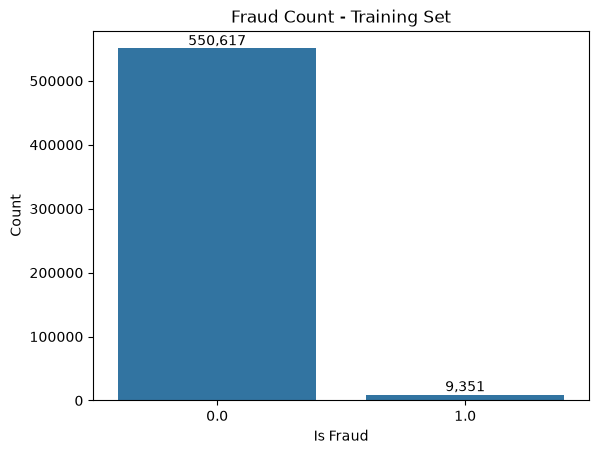

In [13]:
# Visualize counts of target variable
ax = sns.countplot(data=eda, x=TARGET_COL)
ax.bar_label(ax.containers[0], fmt='{:,.0f}')

plt.title('Fraud Count - Training Set')
plt.xlabel('Is Fraud')
plt.ylabel('Count')

plt.show()

### 4.2 Numerical Features

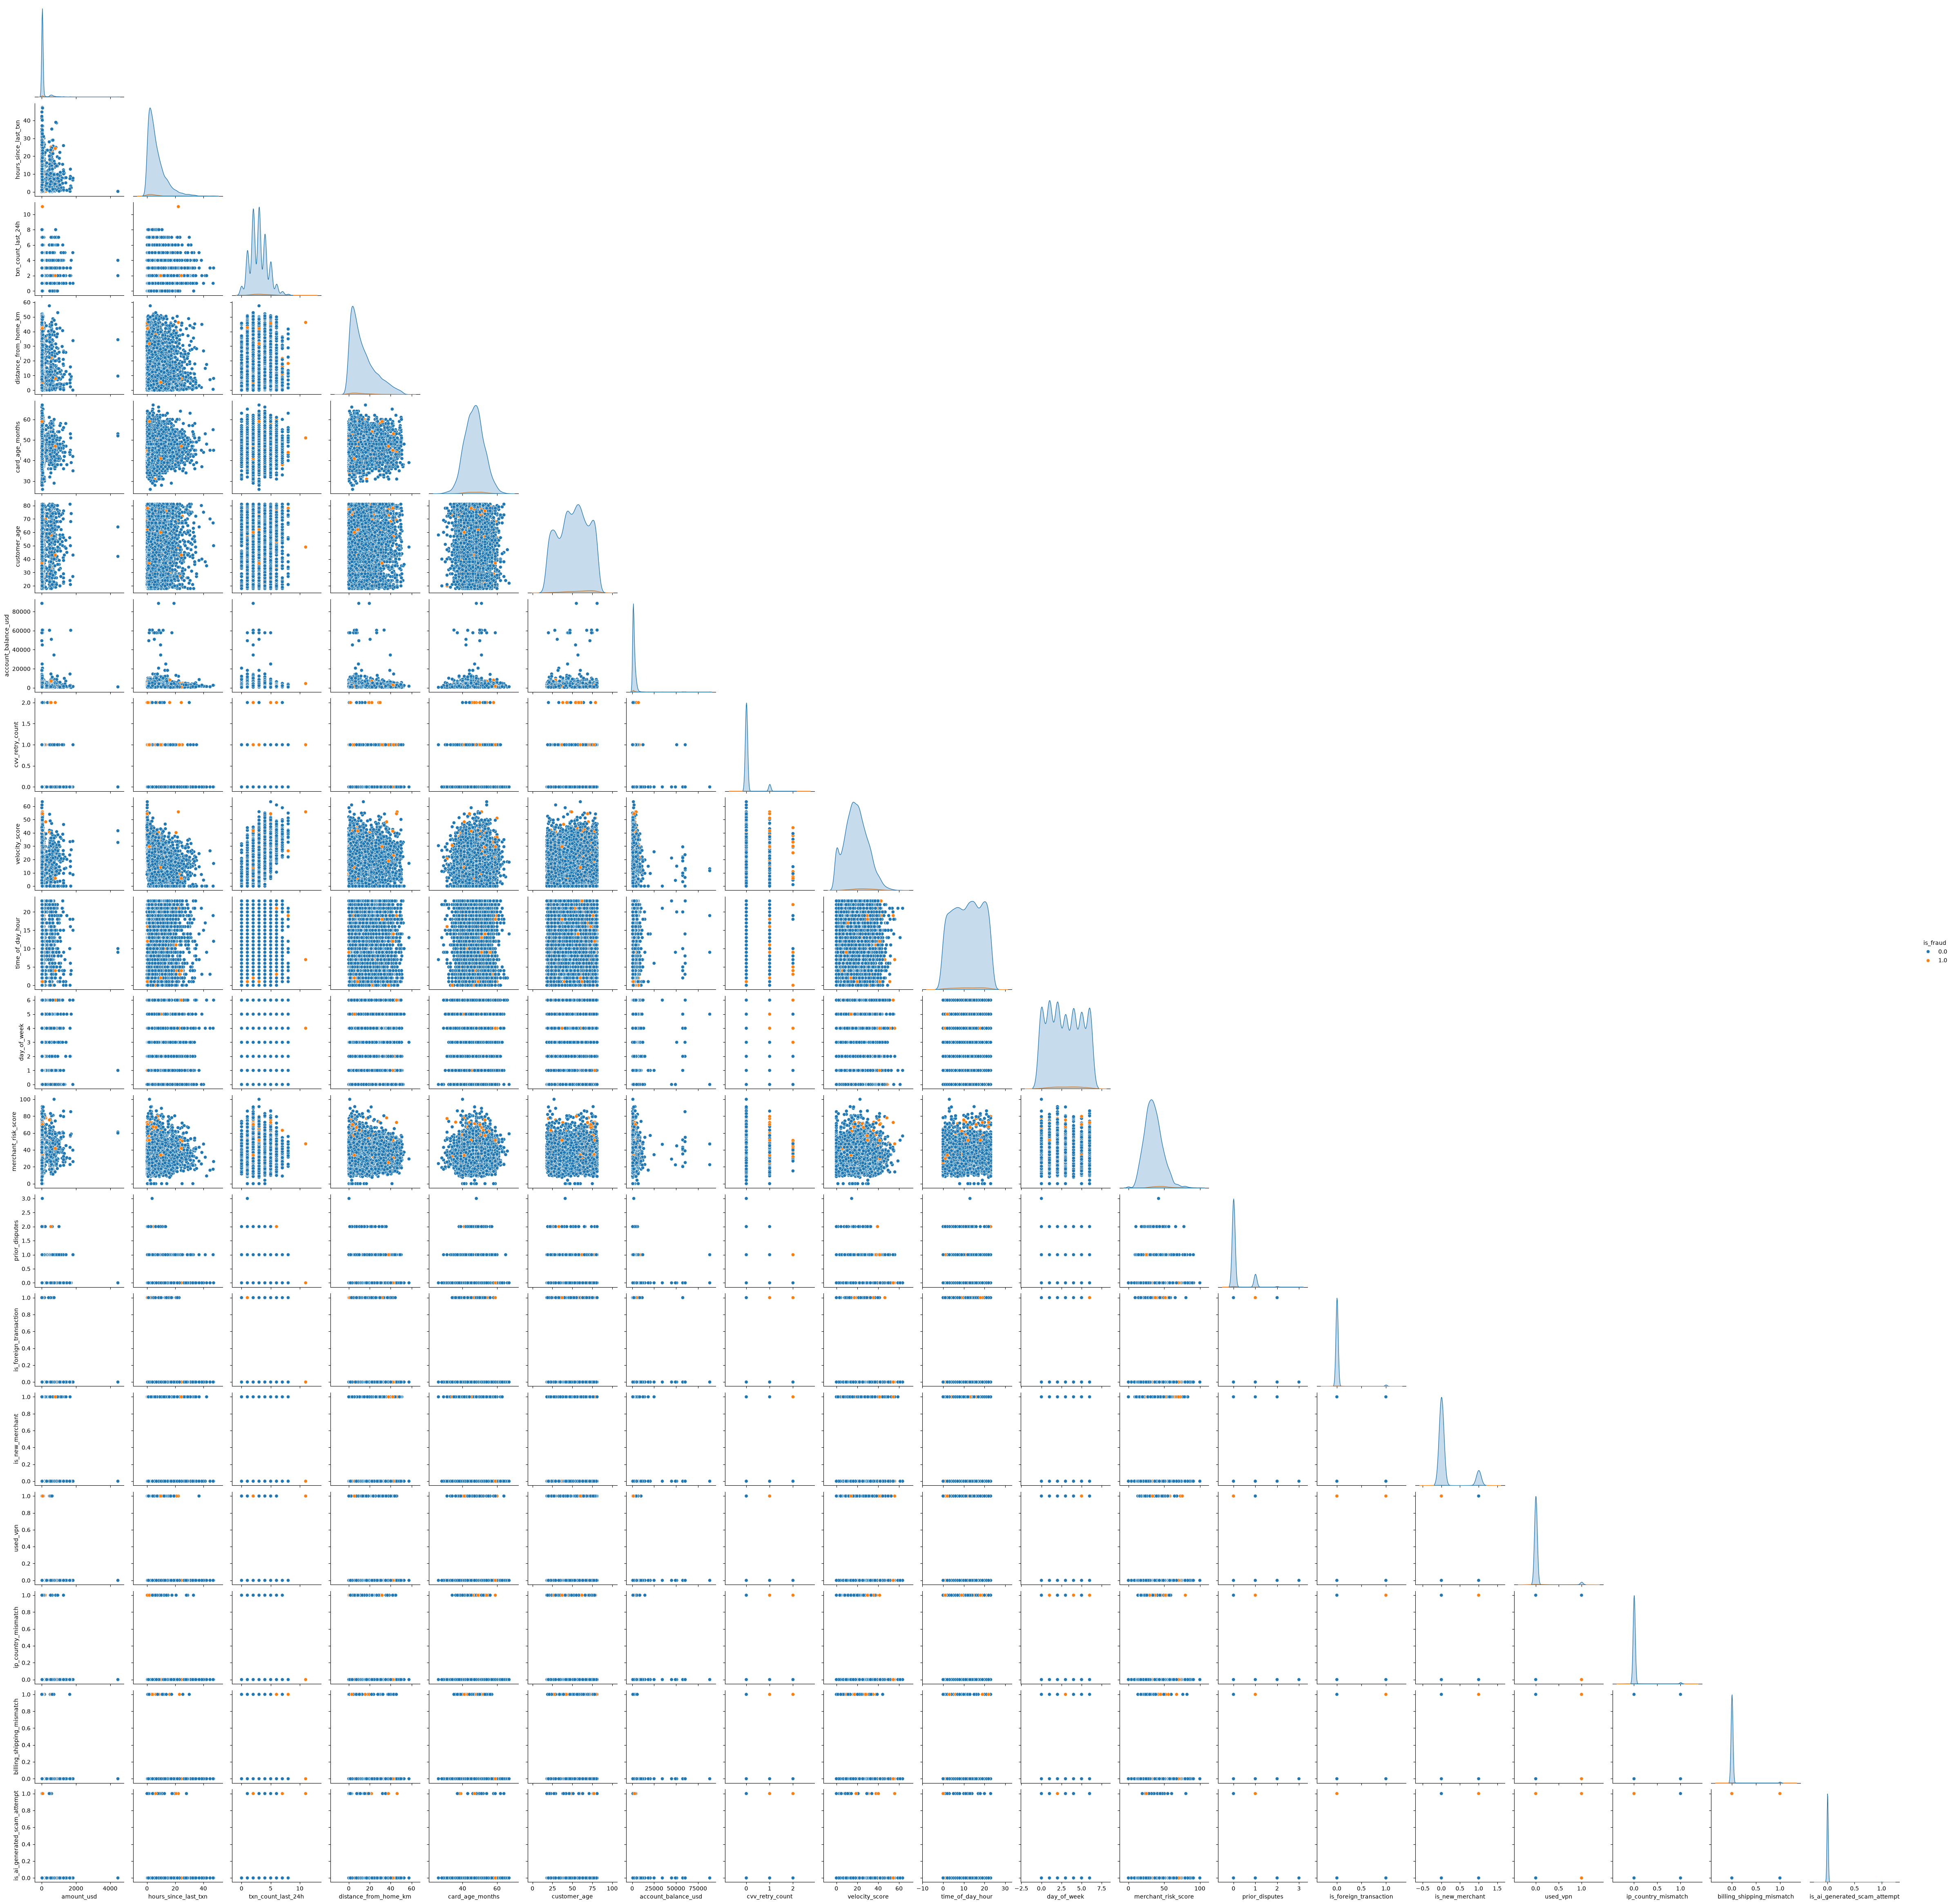

In [14]:
# Paiplot of numerical features
sns.pairplot(
    eda.sample(n = 5000, random_state = RANDOM_STATE),
    hue = TARGET_COL,
    corner = True
)

plt.show()



### 4.3 Categorical Features

In [15]:
# Define categorical columns
categorical_features = eda.select_dtypes(include=['str']).columns.to_list()

def cat_by(col):
    return eda.groupby(col)[TARGET_COL].mean()

for col in categorical_features:
    print(f"\n--- {col} ---")
    rates = cat_by(col)
    print(rates.map(lambda x: f"{x:.0%}"))


--- merchant_category ---
merchant_category
Crypto Exchange    6%
Electronics        3%
Fuel               1%
Gaming             6%
Gift Cards         7%
Groceries          1%
Healthcare         1%
Online Retail      1%
Restaurants        1%
Streaming          2%
Travel             2%
Utilities          1%
Name: is_fraud, dtype: str

--- card_type ---
card_type
Amex          2%
Discover      2%
Mastercard    2%
RuPay         2%
Visa          2%
Name: is_fraud, dtype: str

--- auth_method ---
auth_method
3D Secure            1%
Biometric            0%
No Authentication    6%
OTP                  1%
PIN                  1%
Name: is_fraud, dtype: str

--- channel ---
channel
ATM            2%
Contactless    2%
In-App         2%
Online         2%
POS            2%
Name: is_fraud, dtype: str

--- device_type ---
device_type
ATM Machine      2%
Android Phone    2%
Mac              2%
POS Terminal     2%
Smart Watch      2%
Tablet           2%
Windows PC       2%
iPhone           2%
Name: is

`merchant_category`, and `auth_method` look promising for signal.

### 4.4 Missing Values

In [16]:
missing = X_train.isnull().mean().sort_values(ascending=False)
missing[missing > 0].round(2) * 100


Series([], dtype: float64)

## 5.0 Preprocessing

In [17]:
# Convert boolean columns to integers
X_train[X_train.select_dtypes(include='bool').columns] = X_train[X_train.select_dtypes(include='bool').columns].astype(int)
X_dev[X_dev.select_dtypes(include='bool').columns] = X_dev[X_dev.select_dtypes(include='bool').columns].astype(int)

# Convert target variable to integer
y_train = y_train.astype(int)
y_dev = y_dev.astype(int)

In [18]:
# One-hot encode categorical features
categorical_transformer = Pipeline([
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

In [19]:
# Combine numeric and categorical steps into a single preprocessor
preprocessor = ColumnTransformer([('cat', categorical_transformer, categorical_features)], remainder = 'passthrough')

In [20]:
# Function to make model pipeline
def make_pipeline(model, scale=False):
    """Wrap a model in the preprocessing pipeline."""
    steps = [('preprocessor', preprocessor)]
    if scale:
        steps.append(('scaler', StandardScaler()))
    steps.append(('model', model))
    return Pipeline(steps)

## 6.0 Modeling

In [21]:
# Store fitted models and their dev scores for later comparison
models = {}
results = {}


def evaluate(name, model):
    """Fit on the training set, score ROC-AUC on the dev set, record the result,
    and visualize the ROC curve, confusion matrix, and classification report.
    """
    start = time.perf_counter()

    model.fit(X_train, y_train)

    # Predicted probabilities for the positive class (needed for ROC-AUC)
    proba = model.predict_proba(X_dev)[:, 1]
    preds = model.predict(X_dev)

    roc_auc = roc_auc_score(y_dev, proba)
    elapsed = time.perf_counter() - start

    models[name] = model
    results[name] = {'ROC_AUC': roc_auc, 'fit_seconds': elapsed}
    print(f'{name:<22} ROC-AUC = {roc_auc:.4f}   ({elapsed:.1f}s)')
    print(f'\nClassification Report — {name}:')
    print(classification_report(y_dev, preds))

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # ROC curve
    fpr, tpr, _ = roc_curve(y_dev, proba)
    axes[0].plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.3f})')
    axes[0].plot([0, 1], [0, 1], color='red', linestyle='--', linewidth=1, label='Chance')
    axes[0].set_xlabel('False Positive Rate')
    axes[0].set_ylabel('True Positive Rate')
    axes[0].set_title(f'{name}: ROC Curve')
    axes[0].legend(loc='lower right')

    # Confusion matrix
    cm = confusion_matrix(y_dev, preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(ax=axes[1], cmap='Blues', colorbar=False)
    axes[1].set_title(f'{name}: Confusion Matrix')

    plt.tight_layout()
    plt.show()

    return model

### 6.1 Model Training

#### 6.1.1 Logistic Regression

Logistic Regression    ROC-AUC = 0.9401   (1.2s)

Classification Report — Logistic Regression:
              precision    recall  f1-score   support

           0       1.00      0.88      0.94    137654
           1       0.11      0.85      0.19      2338

    accuracy                           0.88    139992
   macro avg       0.55      0.86      0.56    139992
weighted avg       0.98      0.88      0.92    139992



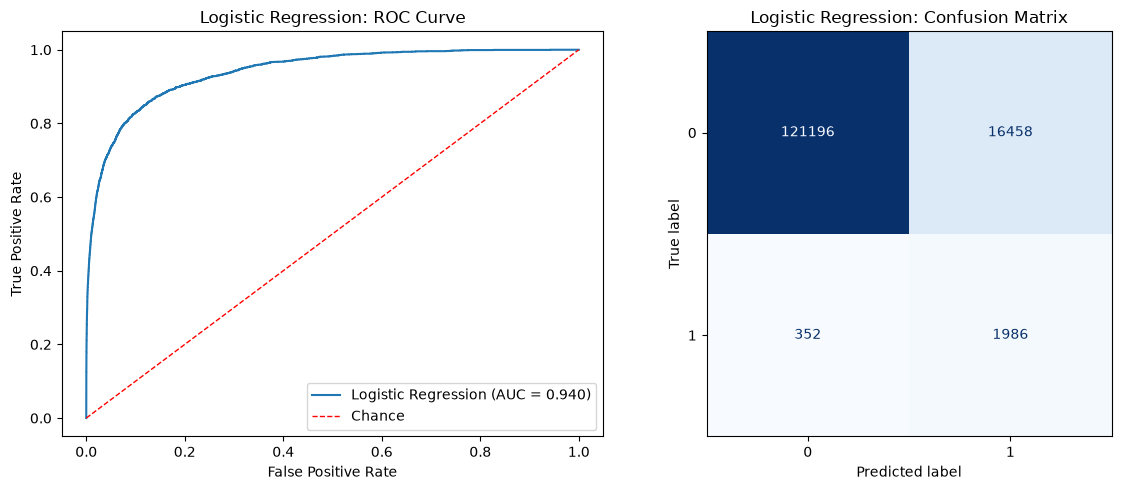

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['amount_usd','hours_since_last_txn','txn_count_last_24h',..., 'ip_country_mismatch','billing_shipping_mismatch', 'is_ai_generated_scam_attempt']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (defa

In [22]:
evaluate('Logistic Regression', make_pipeline(
    LogisticRegression(
        class_weight = 'balanced',
        max_iter = 2000,
        random_state = RANDOM_STATE
    ),
    scale=True
))

#### 6.1.2 LightGBM

LightGBM               ROC-AUC = 0.9418   (12.8s)

Classification Report — LightGBM:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99    137654
           1       0.73      0.30      0.43      2338

    accuracy                           0.99    139992
   macro avg       0.86      0.65      0.71    139992
weighted avg       0.98      0.99      0.98    139992



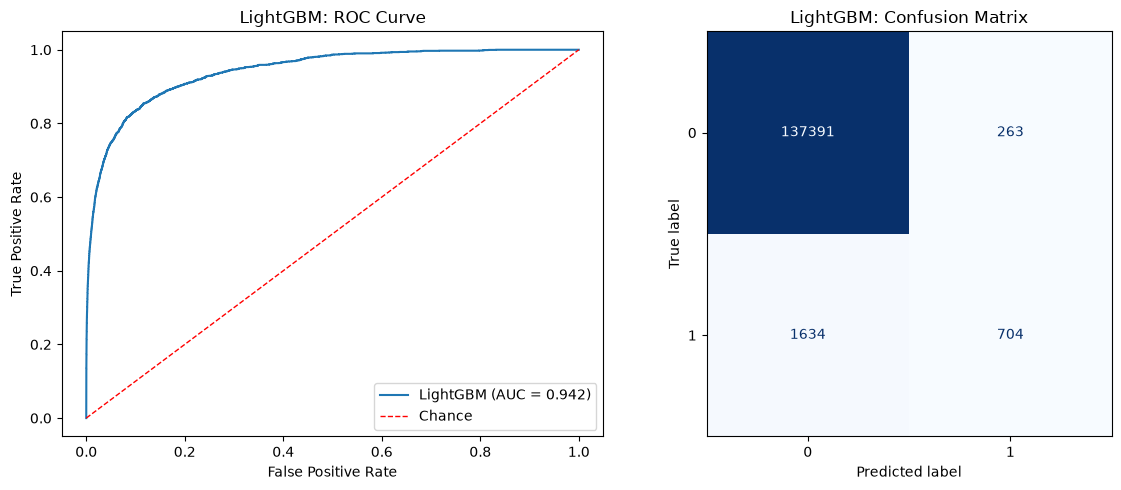

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['amount_usd','hours_since_last_txn','txn_count_last_24h',..., 'ip_country_mismatch','billing_shipping_mismatch', 'is_ai_generated_scam_attempt']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of

In [23]:
evaluate('LightGBM', make_pipeline(
    LGBMClassifier(
        n_estimators=1000,        
        learning_rate=0.05,
        num_leaves=63,            
        max_depth=-1,
        min_child_samples=100,    
        subsample=0.8,
        subsample_freq=1,        
        colsample_bytree=0.7,
        reg_alpha=0.1,
        reg_lambda=1.0,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=-1
    )
))

#### 6.1.4 XGBoost

XGBoost                ROC-AUC = 0.9427   (9.5s)

Classification Report — XGBoost:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99    137654
           1       0.73      0.32      0.44      2338

    accuracy                           0.99    139992
   macro avg       0.86      0.66      0.72    139992
weighted avg       0.98      0.99      0.98    139992



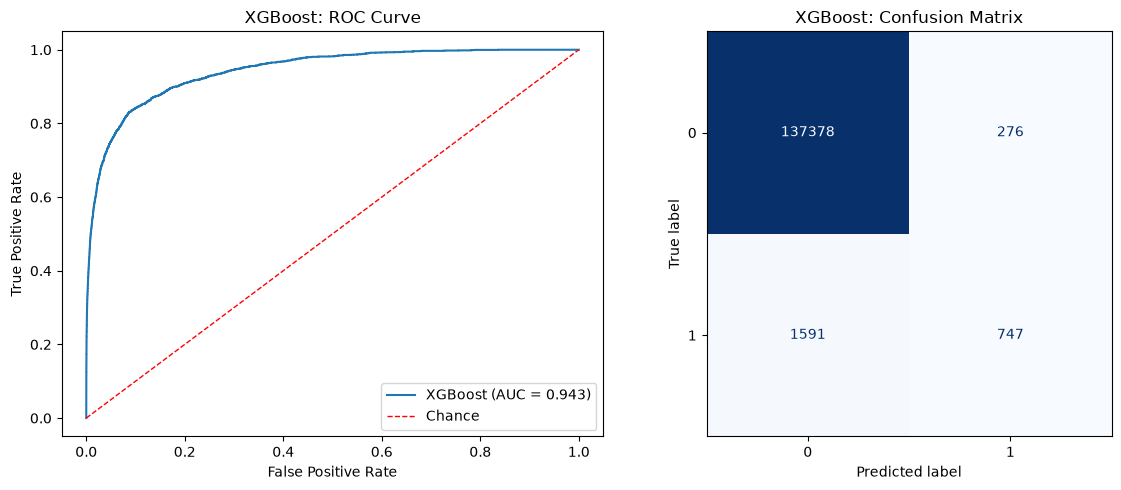

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['amount_usd','hours_since_last_txn','txn_count_last_24h',..., 'ip_country_mismatch','billing_shipping_mismatch', 'is_ai_generated_scam_attempt']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of

In [24]:
evaluate('XGBoost', make_pipeline(
    XGBClassifier(
        n_estimators=1000,         
        learning_rate=0.05,
        max_depth=6,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.7,
        reg_alpha=0.1,
        reg_lambda=1.0,
        tree_method='hist',        
        eval_metric='auc',
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
))

### 6.2 Model Comparison

In [25]:
# Rank models by dev AUC
leaderboard = round(pd.DataFrame(results).T.sort_values('ROC_AUC', ascending=False),4)
leaderboard

,ROC_AUC,fit_seconds
XGBoost,0.9427,9.5281
LightGBM,0.9418,12.7839
Logistic Regression,0.9401,1.1603


In [26]:
# Best model
best_name = leaderboard['ROC_AUC'].idxmax()
best_model = models[best_name]

print(f'Selected model: {best_name}')

Selected model: XGBoost


### 6.3 Cross Validation

In [27]:
scoring = {
    'roc_auc': 'roc_auc',
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1'
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_results = cross_validate(best_model, X_train, y_train, cv=cv, scoring=scoring)

print(f"CV ROC-AUC:   {cv_results['test_roc_auc'].mean():.4f} ± {cv_results['test_roc_auc'].std():.4f}")
print(f"CV Accuracy:  {cv_results['test_accuracy'].mean():.4f} ± {cv_results['test_accuracy'].std():.4f}")
print(f"CV Precision: {cv_results['test_precision'].mean():.4f} ± {cv_results['test_precision'].std():.4f}")
print(f"CV Recall:    {cv_results['test_recall'].mean():.4f} ± {cv_results['test_recall'].std():.4f}")
print(f"CV F1:        {cv_results['test_f1'].mean():.4f} ± {cv_results['test_f1'].std():.4f}")



CV ROC-AUC:   0.9442 ± 0.0019
CV Accuracy:  0.9865 ± 0.0003
CV Precision: 0.7265 ± 0.0206
CV Recall:    0.3109 ± 0.0108
CV F1:        0.4354 ± 0.0132


### 6.4 Hyperparameter Tuning

In [28]:
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 300, 1500),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 20),   # ~ min_child_samples
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 0, 1),
        'reg_lambda': trial.suggest_float('reg_lambda', 0, 2),
        'gamma': trial.suggest_float('gamma', 0, 0.5),                      # ~ min_split_gain
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1, 5),  # tune class-imbalance handling
        'random_state': RANDOM_STATE,
        'n_jobs': 1,           # single-threaded per fold
        'verbosity': 0,
        'tree_method': 'hist',
        'eval_metric': 'auc',
    }

    model = make_pipeline(XGBClassifier(**params))

    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)  # parallelism lives here instead
    return scores.mean()

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=10, n_jobs=1, show_progress_bar=True)  # show_progress_bar to confirm it's actually moving

[I 2026-11-01 15:21:16,203] A new study created in memory with name: no-name-8039411f-c54a-430e-8446-eef8640701f3


  0%|          | 0/10 [00:00<?, ?it/s]

[I 2026-11-01 15:21:44,742] Trial 0 finished with value: 0.9452380937043815 and parameters: {'n_estimators': 1012, 'learning_rate': 0.010490537595752034, 'max_depth': 7, 'min_child_weight': 8, 'subsample': 0.9421029225413243, 'colsample_bytree': 0.7416630044966411, 'reg_alpha': 0.27277514089307053, 'reg_lambda': 1.3664953367275723, 'gamma': 0.1735578531206342, 'scale_pos_weight': 3.7221031198905945}. Best is trial 0 with value: 0.9452380937043815.
[I 2026-11-01 15:22:22,883] Trial 1 finished with value: 0.9309172738735031 and parameters: {'n_estimators': 1423, 'learning_rate': 0.17843850329569153, 'max_depth': 5, 'min_child_weight': 18, 'subsample': 0.6634727030999216, 'colsample_bytree': 0.7028706908444278, 'reg_alpha': 0.274234665598748, 'reg_lambda': 1.7008867896193307, 'gamma': 0.15784729264293224, 'scale_pos_weight': 1.7648037310548035}. Best is trial 0 with value: 0.9452380937043815.
[I 2026-11-01 15:22:45,332] Trial 2 finished with value: 0.947195990087728 and parameters: {'n_es

In [29]:
# Make final model
final_model = make_pipeline(XGBClassifier(**study.best_params, random_state=RANDOM_STATE, n_jobs=-1))
final_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['amount_usd','hours_since_last_txn','txn_count_last_24h',..., 'ip_country_mismatch','billing_shipping_mismatch', 'is_ai_generated_scam_attempt']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of

## 7.0 Model Evaluation

Final Model            ROC-AUC = 0.9456   (10.0s)

Classification Report — Final Model:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99    137654
           1       0.60      0.42      0.49      2338

    accuracy                           0.99    139992
   macro avg       0.80      0.71      0.74    139992
weighted avg       0.98      0.99      0.98    139992



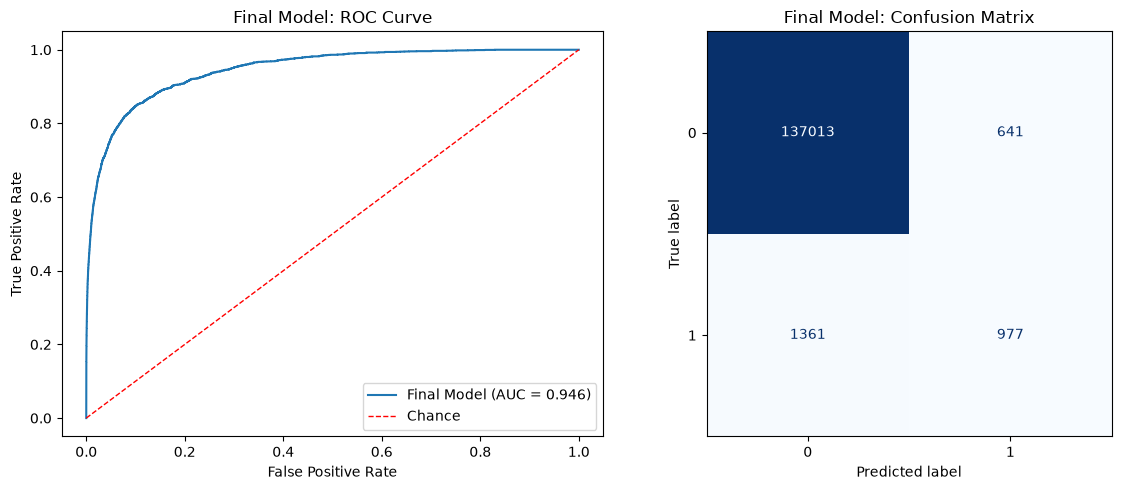

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['amount_usd','hours_since_last_txn','txn_count_last_24h',..., 'ip_country_mismatch','billing_shipping_mismatch', 'is_ai_generated_scam_attempt']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of

In [30]:
evaluate('Final Model', make_pipeline(
    XGBClassifier(
        **study.best_params,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
))

### 7.1 Feature Importance

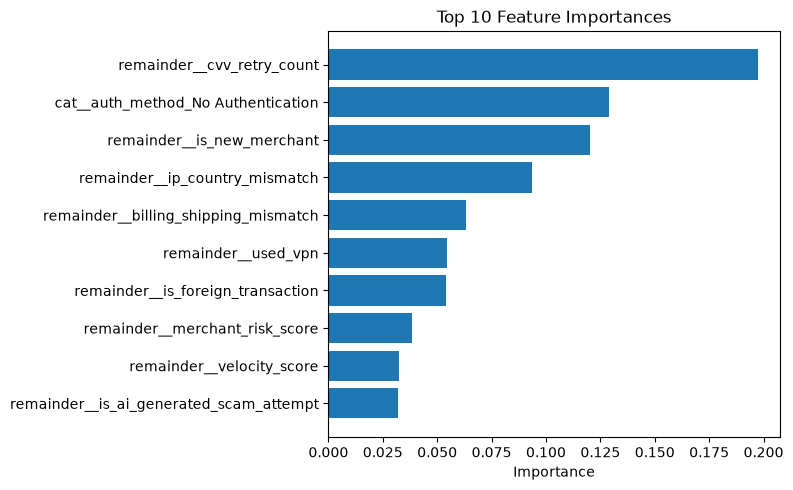

In [31]:
xgb_model = final_model.named_steps['model']
preprocessor_fitted = final_model.named_steps['preprocessor']

feature_names = preprocessor_fitted.get_feature_names_out()
importances = xgb_model.feature_importances_

imp_df = pd.DataFrame({'feature': feature_names, 'importance': importances})

# Keep only the top 10 by importance
imp_df = imp_df.sort_values('importance', ascending=False).head(10)
imp_df = imp_df.sort_values('importance', ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp_df['feature'], imp_df['importance'])
ax.set_xlabel('Importance')
ax.set_title('Top 10 Feature Importances')
plt.tight_layout()
plt.show()

## 8.0 Make Predictions

In [32]:
# Make predictions on test set
y_pred = final_model.predict_proba(test)[:, 1]

# Build submission file
submission = pd.DataFrame({
    'id': test.index,
    'is_fraud': y_pred
})

timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
submission.to_csv(f'{OUTPUT_PATH}submission_{timestamp}.csv', index=False)